# Mapping county health need and care indicators

This notebook is descriptive, not predictive. The first axis is the PLACES-based `NeedScore`. For a cautious quality-related comparison, the second axis is a **readmission-based effectiveness proxy**: counties with lower CMS-reported acute readmission rates score higher. Readmissions are only one imperfect indicator, not a complete measure of effectiveness.

ER visits and Medicare spending are shown separately as utilization/resource-use context. Low ER use or spending is not automatically better, and this analysis does not measure healthcare efficiency or establish causes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
county_need = pd.read_csv(PROJECT_ROOT / "data/processed/county_need_2024.csv")
cms24 = pd.read_csv(PROJECT_ROOT / "data/processed/cms24_county_small.csv")

In [2]:
county_need["CountyFIPS"] = (
    county_need["CountyFIPS"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
cms24["BENE_GEO_CD"] = (
    cms24["BENE_GEO_CD"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

analysis_df = county_need.merge(
    cms24,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner",
    validate="one_to_one",
)

metric_columns = [
    "NeedScore",
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
    "BENES_TOTAL_CNT",
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
    "MA_PRTCPTN_RATE",
    "BENE_DUAL_PCT",
]
for column in metric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

print(f"Merged counties: {len(analysis_df):,}")

Merged counties: 3,142


## Prepare the primary comparison and sensitivity scores

The primary vertical axis will use the readmission measure alone, reversed and standardized. This avoids combining care quality, utilization, and cost into one label. We will also compare that priority group with two alternate summaries: a mean of readmission/ER indicators, and a three-indicator score that additionally treats lower spending as favorable. These alternatives are sensitivity checks, not validated efficiency scores. Using complete cases for all components makes the comparisons use the same counties.

In [3]:
care_indicators = [
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
score_df = analysis_df[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "total_population",
        "NeedScore", "BENES_TOTAL_CNT", "FQHC_RHC_VISITS_PER_1000_BENES",
        "OP_VISITS_PER_1000_BENES", "MA_PRTCPTN_RATE", "BENE_DUAL_PCT",
    ]
    + care_indicators
].dropna(subset=["NeedScore", *care_indicators]).copy()

for column in care_indicators:
    score_df[f"{column}_z"] = (
        score_df[column] - score_df[column].mean()
    ) / score_df[column].std()

score_df["ReadmissionEffectivenessProxy"] = -score_df["ACUTE_HOSP_READMSN_PCT_z"]
score_df["ReadmissionErSummary"] = -score_df[
    ["ACUTE_HOSP_READMSN_PCT_z", "ER_VISITS_PER_1000_BENES_z"]
].mean(axis=1)
score_df["ThreeIndicatorSummary"] = -score_df[
    [f"{column}_z" for column in care_indicators]
].mean(axis=1)

score_df[[
    "NeedScore", "ReadmissionEffectivenessProxy",
    "ReadmissionErSummary", "ThreeIndicatorSummary",
]].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,2996.0,1.360233e+00,2.065968,-4.492298,-0.075007,1.162341,2.866045,9.314433
ReadmissionEffectivenessProxy,2996.0,7.328361e-16,1.000000,-6.968722,-0.608394,-0.015593,0.613235,5.555426
ReadmissionErSummary,2996.0,6.640586e-17,0.817728,-4.961072,-0.512760,0.013324,0.490646,4.753985
ThreeIndicatorSummary,2996.0,1.849878e-16,0.747930,-4.610358,-0.441991,0.019198,0.472570,4.344204


## Visualize need versus the readmission proxy

The quadrant with above-median need and a below-median readmission proxy contains counties with higher need and higher readmission rates. Call these **priority candidates for investigation**, not proven underperformers. A high readmission rate can have multiple causes.

In [4]:
need_cutoff = score_df["NeedScore"].median()
performance_cutoff = score_df["ReadmissionEffectivenessProxy"].median()

def assign_quadrant(row):
    high_need = row["NeedScore"] >= need_cutoff
    higher_readmission_proxy = row["ReadmissionEffectivenessProxy"] >= performance_cutoff
    if high_need and not higher_readmission_proxy:
        return "High need / higher readmissions"
    if high_need and higher_readmission_proxy:
        return "High need / lower readmissions"
    if not high_need and higher_readmission_proxy:
        return "Lower need / lower readmissions"
    return "Lower need / higher readmissions"

score_df["Quadrant"] = score_df.apply(assign_quadrant, axis=1)
score_df["Priority"] = score_df["Quadrant"].eq("High need / higher readmissions")
score_df["Quadrant"].value_counts().to_frame("count")

,count
Quadrant,
Lower need / lower readmissions,849
High need / higher readmissions,848
High need / lower readmissions,650
Lower need / higher readmissions,649


## Test stricter priority cutoffs

Median splits flag about half the counties on each axis. As a sensitivity check, define a stricter group using the top quartile of NeedScore and the top quartile of the observed readmission rate. It will usually be a subset of the median-based priority group; report the overlap and any exceptions rather than assuming that. Quantile ties can make group sizes slightly larger than exactly 25%.

In [5]:
need_q75 = score_df["NeedScore"].quantile(0.75)
readmission_q75 = score_df["ACUTE_HOSP_READMSN_PCT"].quantile(0.75)
score_df["StrictPriority"] = (
    score_df["NeedScore"].ge(need_q75)
    & score_df["ACUTE_HOSP_READMSN_PCT"].ge(readmission_q75)
)

strict_count = int(score_df["StrictPriority"].sum())
median_priority_count = int(score_df["Priority"].sum())
strict_outside_median = int(
    (score_df["StrictPriority"] & ~score_df["Priority"]).sum()
)
threshold_summary = pd.Series({
    "NeedScore 75th-percentile cutoff": need_q75,
    "Readmission-rate 75th-percentile cutoff": readmission_q75,
    "Median-based priority counties": median_priority_count,
    "Top-quartile priority counties": strict_count,
    "Median-priority group retained (%)": round(
        100 * strict_count / median_priority_count, 1
    ),
    "Strict counties outside median priority": strict_outside_median,
})
threshold_summary

NeedScore 75th-percentile cutoff             2.866045
Readmission-rate 75th-percentile cutoff      0.188200
Median-based priority counties             848.000000
Top-quartile priority counties             289.000000
Median-priority group retained (%)          34.100000
Strict counties outside median priority      0.000000
dtype: float64

In [6]:
strict_priority_counties = (
    score_df[score_df["StrictPriority"]]
    .sort_values(
        ["NeedScore", "ACUTE_HOSP_READMSN_PCT"],
        ascending=[False, False],
    )
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT",
        "NeedScore", "ACUTE_HOSP_READMSN_PCT",
    ]]
)
strict_priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT
2413,SD,Oglala Lakota,46102,1458.0,7.440376,0.2380
3093,WV,Mingo,54059,6843.0,7.257157,0.2750
2587,TX,Dimmit,48127,1983.0,7.117166,0.2471
1067,KY,Magoffin,21153,3366.0,7.080552,0.1988
1543,MS,Humphreys,28053,2034.0,7.050507,0.2273
150,AR,Phillips,05107,4320.0,7.017548,0.2014
1146,LA,Madison,22065,2102.0,6.841615,0.1899
1058,KY,Lee,21129,1841.0,6.698802,0.3025
2422,SD,Todd,46121,1019.0,6.685771,0.2261
507,GA,Randolph,13243,1741.0,6.612370,0.2600


## Check whether priority counties depend on the score definition

Use the same complete-case counties and the same median need cutoff for each version. The readmission-only proxy is the primary definition. The other versions add ER visits and then spending; comparing their overlap shows how sensitive the flagged group is to assumptions about what counts as better care.

In [7]:
score_definitions = {
    "Readmissions only (primary)": "ReadmissionEffectivenessProxy",
    "Readmissions + ER visits": "ReadmissionErSummary",
    "Readmissions + ER + spending": "ThreeIndicatorSummary",
}
primary_priority = score_df["Priority"]
sensitivity_rows = []

for label, column in score_definitions.items():
    is_priority = (
        score_df["NeedScore"].ge(need_cutoff)
        & score_df[column].lt(score_df[column].median())
    )
    intersection = (is_priority & primary_priority).sum()
    union = (is_priority | primary_priority).sum()
    sensitivity_rows.append({
        "Score definition": label,
        "Priority counties": int(is_priority.sum()),
        "Same as primary": int(intersection),
        "Overlap with primary (%)": round(100 * intersection / primary_priority.sum(), 1),
        "Jaccard similarity": round(intersection / union, 3) if union else 1.0,
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table

,Score definition,Priority counties,Same as primary,Overlap with primary (%),Jaccard similarity
0,Readmissions only (primary),848,848,100.0,1.000
1,Readmissions + ER visits,947,763,90.0,0.739
2,Readmissions + ER + spending,970,732,86.3,0.674


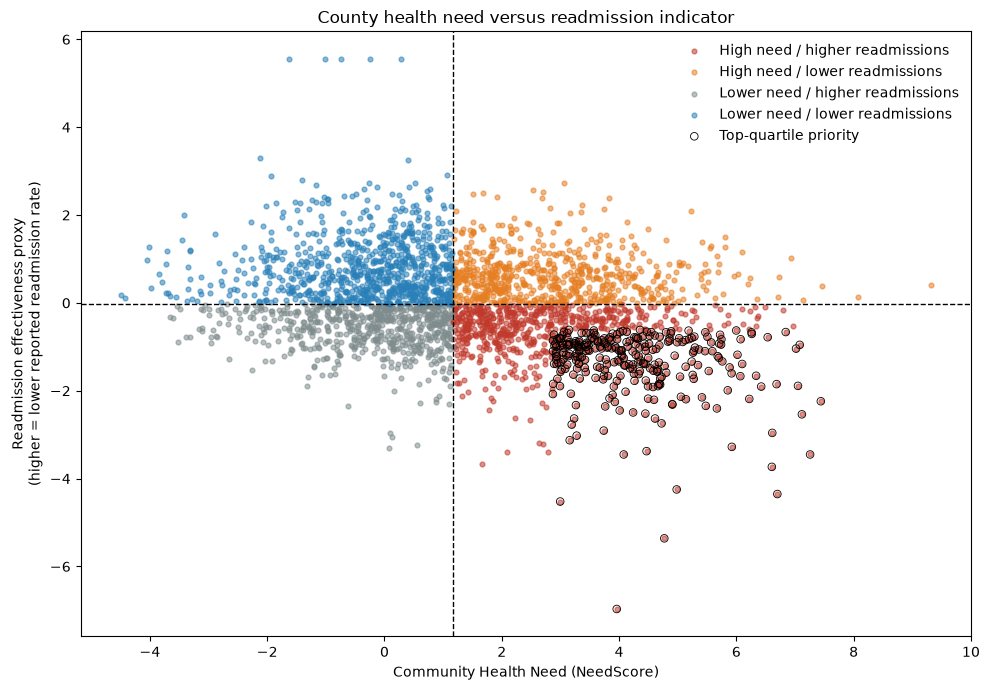

In [8]:
colors = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / lower readmissions": "#2980b9",
    "Lower need / higher readmissions": "#7f8c8d",
}

fig, ax = plt.subplots(figsize=(10, 7))
for quadrant, group in score_df.groupby("Quadrant"):
    ax.scatter(
        group["NeedScore"],
        group["ReadmissionEffectivenessProxy"],
        s=12,
        alpha=0.55,
        label=quadrant,
        color=colors[quadrant],
    )
strict_group = score_df[score_df["StrictPriority"]]
ax.scatter(
    strict_group["NeedScore"],
    strict_group["ReadmissionEffectivenessProxy"],
    s=30,
    facecolors="none",
    edgecolors="black",
    linewidths=0.6,
    label="Top-quartile priority",
    zorder=5,
)
ax.axvline(need_cutoff, color="black", linestyle="--", linewidth=1)
ax.axhline(performance_cutoff, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Community Health Need (NeedScore)")
ax.set_ylabel("Readmission effectiveness proxy\n(higher = lower reported readmission rate)")
ax.set_title("County health need versus readmission indicator")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

In [9]:
priority_counties = (
    score_df[score_df["Priority"]]
    .sort_values(["NeedScore", "ReadmissionEffectivenessProxy"], ascending=[False, True])
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "ReadmissionEffectivenessProxy", "BENES_TOTAL_CNT", *care_indicators,
    ]]
)
priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,NeedScore,ReadmissionEffectivenessProxy,BENES_TOTAL_CNT,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,TOT_MDCR_STDZD_PYMT_PC
2413,SD,Oglala Lakota,46102,7.440376,-2.239415,1458.0,601.8237,0.2380,17629.81
3093,WV,Mingo,54059,7.257157,-3.451218,6843.0,860.5372,0.2750,11085.57
2587,TX,Dimmit,48127,7.117166,-2.537453,1983.0,890.9774,0.2471,16632.19
1067,KY,Magoffin,21153,7.080552,-0.955559,3366.0,664.9810,0.1988,11434.53
1543,MS,Humphreys,28053,7.050507,-1.888975,2034.0,658.9674,0.2273,14724.98
150,AR,Phillips,05107,7.017548,-1.040713,4320.0,500.0000,0.2014,11653.10
61,AL,Greene,01063,6.961679,-0.536341,2367.0,543.7616,0.1860,11800.14
1146,LA,Madison,22065,6.841615,-0.664071,2102.0,902.4123,0.1899,18872.13
35,AL,Bullock,01011,6.791085,-0.153149,2441.0,482.6923,0.1743,12279.03
1058,KY,Lee,21129,6.698802,-4.351883,1841.0,668.8453,0.3025,12957.29


## Check Medicare beneficiary counts before interpreting rates

County rates based on fewer beneficiaries can be less stable. This check compares beneficiary-count distributions for priority and other counties, then reports priority shares across beneficiary-count quartiles. It does not impose an arbitrary minimum-count cutoff or remove counties; use it to identify results that deserve extra caution.

In [10]:
denominator_summary = score_df.groupby("Priority")["BENES_TOTAL_CNT"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)
denominator_summary

,count,mean,std,min,10%,25%,50%,75%,90%,max
Priority,,,,,,,,,,
False,2148.0,27410.820298,70357.767437,117.0,1615.7,3253.0,7983.5,22401.25,63603.4,1718250.0
True,848.0,12458.452830,25368.454238,225.0,1726.9,3187.5,6157.0,11696.00,23078.0,360938.0


In [11]:
score_df["BeneficiaryCountQuartile"] = pd.qcut(
    score_df["BENES_TOTAL_CNT"],
    q=4,
    duplicates="drop",
)
denominator_profile = (
    score_df.groupby("BeneficiaryCountQuartile", observed=True)
    .agg(
        Counties=("CountyFIPS", "count"),
        Priority_counties=("Priority", "sum"),
        Priority_share=("Priority", "mean"),
        Median_ER_visits=("ER_VISITS_PER_1000_BENES", "median"),
        Median_readmission_rate=("ACUTE_HOSP_READMSN_PCT", "median"),
    )
)
denominator_profile["Priority_share_pct"] = (
    100 * denominator_profile["Priority_share"]
).round(1)
denominator_profile.drop(columns="Priority_share")

,Counties,Priority_counties,Median_ER_visits,Median_readmission_rate,Priority_share_pct
BeneficiaryCountQuartile,,,,,
"(116.999, 3243.75]",749,214,592.1569,0.1616,28.6
"(3243.75, 7153.5]",749,272,628.6318,0.1667,36.3
"(7153.5, 18290.25]",749,242,629.2290,0.1696,32.3
"(18290.25, 1718250.0]",749,120,589.7010,0.1774,16.0


In [12]:
priority_counties.sort_values("BENES_TOTAL_CNT").head(15)[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT",
        "NeedScore", "ACUTE_HOSP_READMSN_PCT",
        "ER_VISITS_PER_1000_BENES",
    ]
]

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT,ER_VISITS_PER_1000_BENES
2370,SD,Buffalo,46017,225.0,4.771342,0.3333,1103.8961
988,KS,Wallace,20199,389.0,1.383764,0.1739,510.2639
1797,ND,Sioux,38085,459.0,6.604873,0.2836,495.7265
2397,SD,Jackson,46071,499.0,3.959958,0.3824,568.1063
2386,SD,Faulk,46049,606.0,1.329873,0.2000,410.3194
2377,SD,Corson,46031,608.0,5.039969,0.2209,793.1034
2160,OK,Harmon,40057,650.0,3.996137,0.1881,742.1687
2671,TX,Lipscomb,48295,676.0,1.325523,0.1899,709.4431
2753,TX,Upton,48461,679.0,3.971430,0.1842,864.8649
2567,TX,Collingsworth,48087,692.0,2.935019,0.1774,872.8070


## Compare individual indicators for priority candidates

The priority label is based only on NeedScore and the readmission proxy. Compare ER visits and spending separately: they provide context but do not define effectiveness.

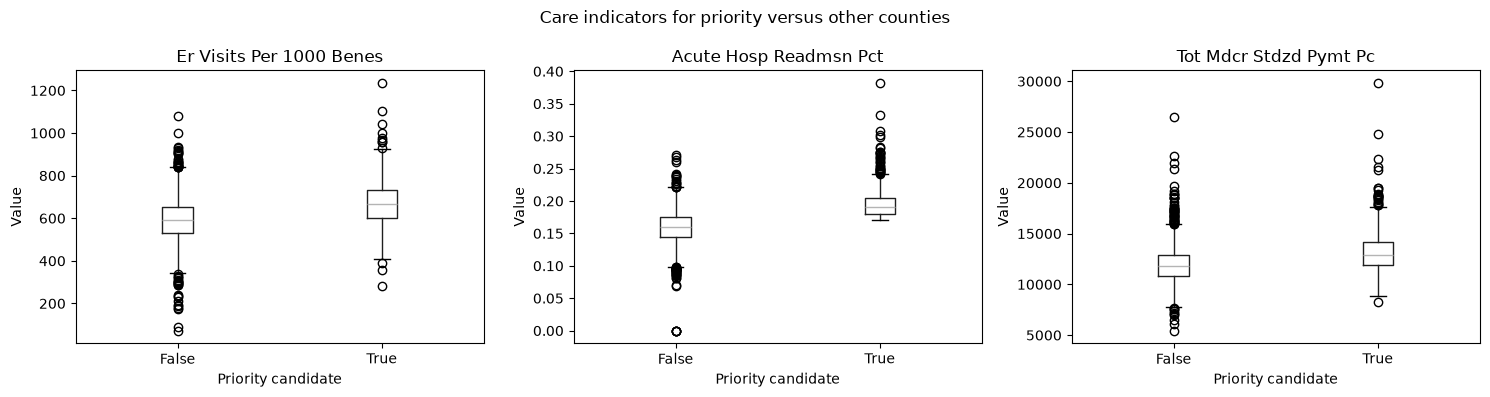

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, care_indicators):
    score_df.boxplot(column=column, by="Priority", ax=ax, grid=False)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Priority candidate")
    ax.set_ylabel("Value")
fig.suptitle("Care indicators for priority versus other counties")
plt.tight_layout()
plt.show()

## Map need, readmissions, ER visits, and spending

These county choropleths keep each measure separate so the map does not conceal tradeoffs in a composite. The notebook downloads the official [2024 Census TIGER/Line county boundaries](https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip) and caches them under `data/raw/` (ignored by Git). Install the small shapefile reader once with `python -m pip install -r requirements-mapping.txt`. The map separates the contiguous U.S., Alaska, and Hawaii; territories are excluded. Colors are clipped to each measure's 2nd and 98th percentiles to make county patterns easier to see; use the raw data/table for extremes.

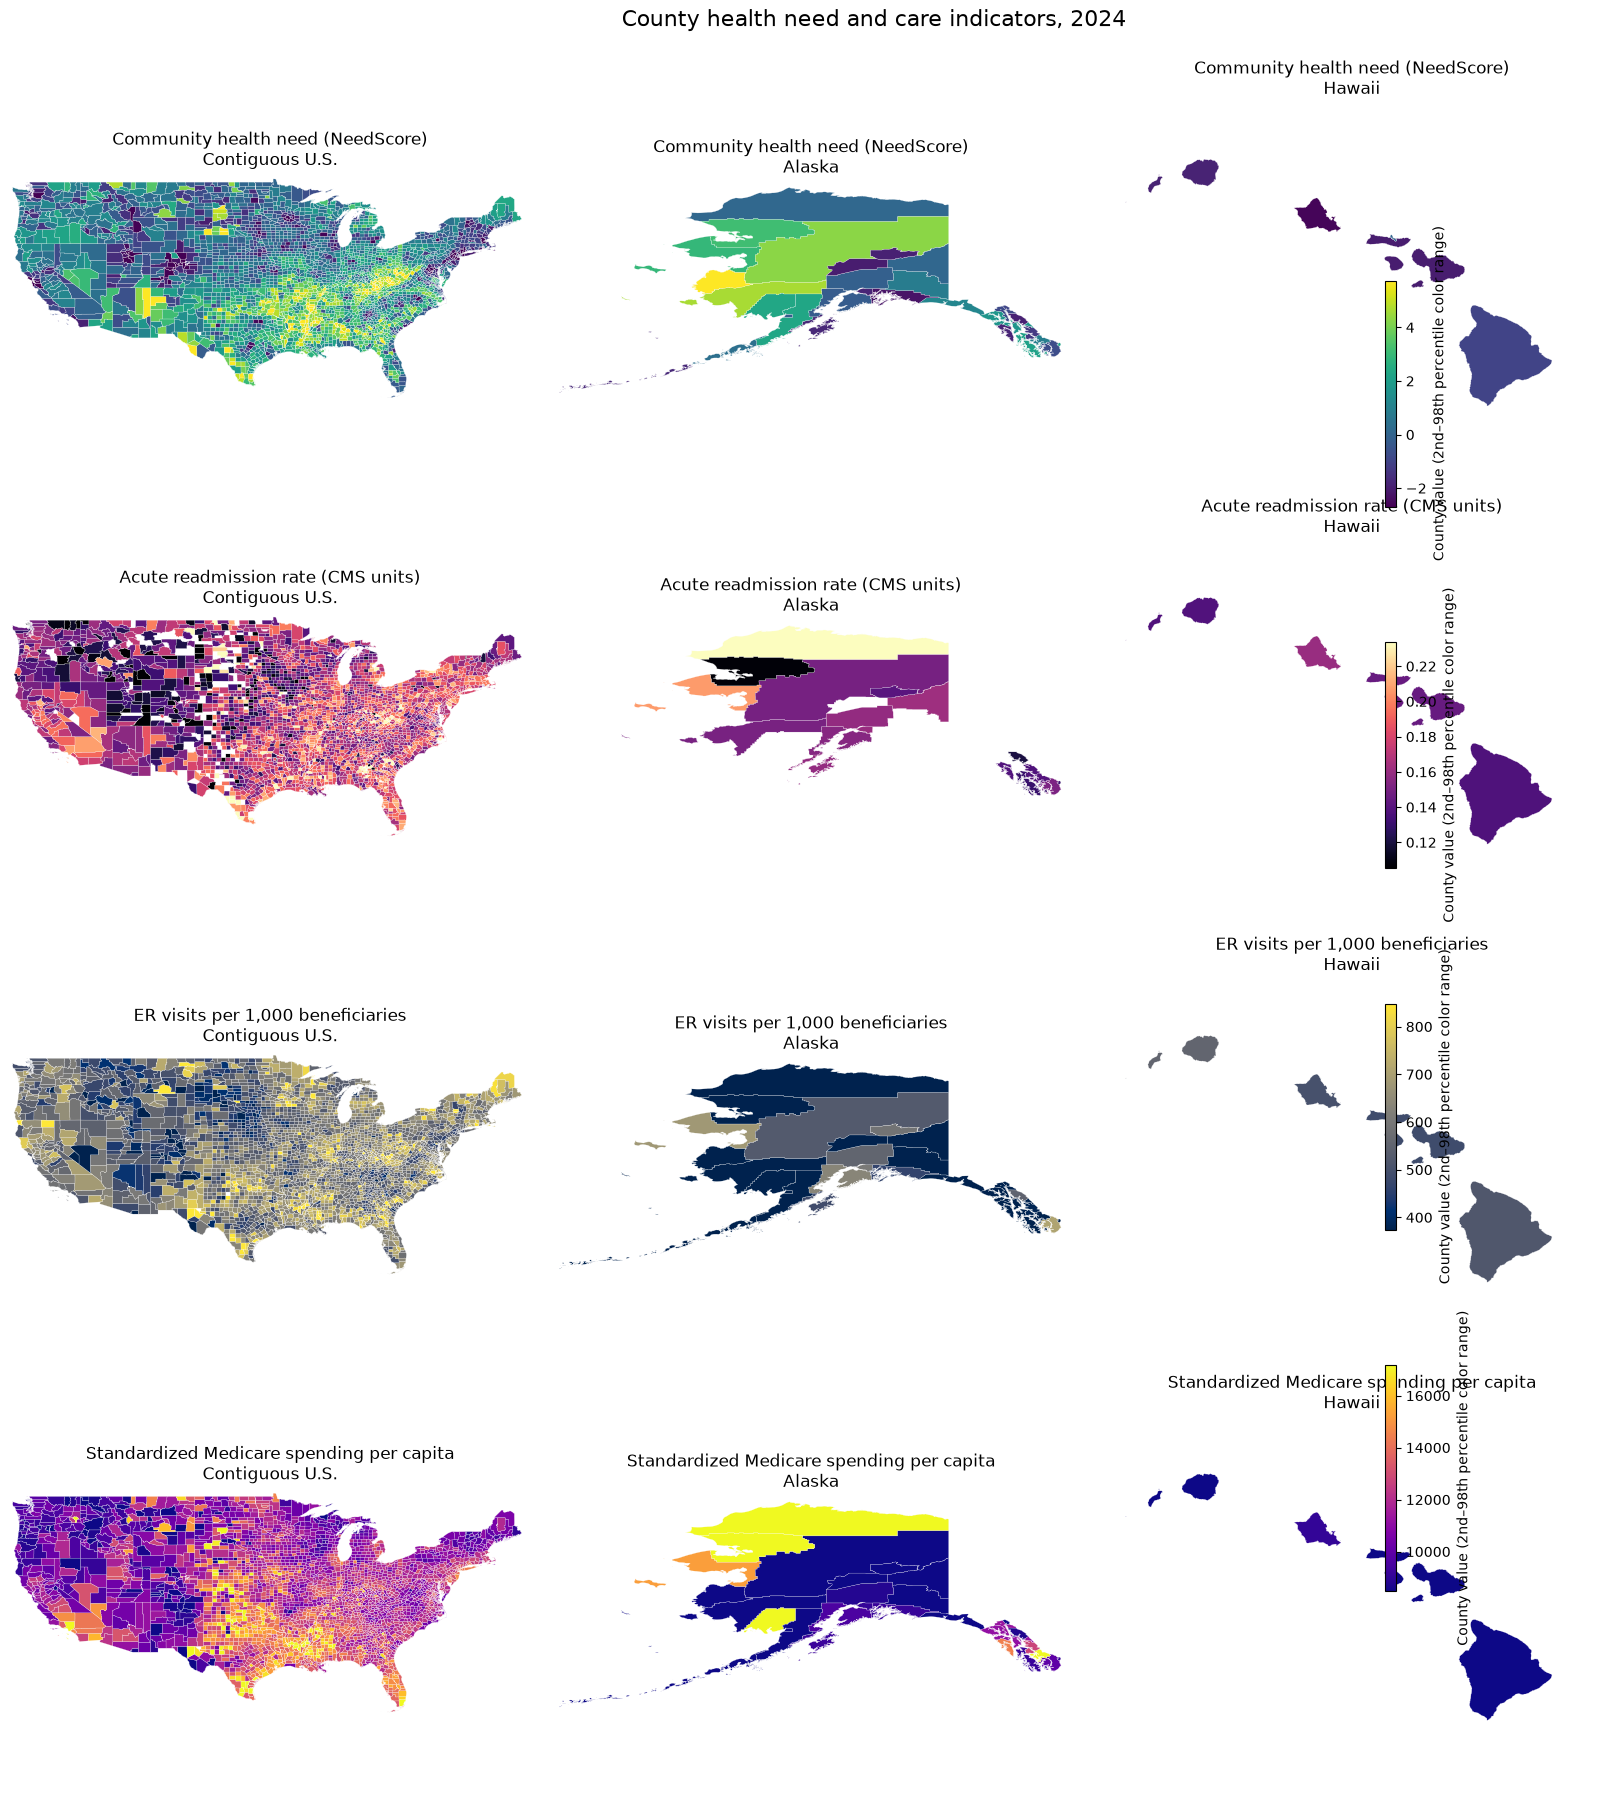

County polygons with data by region:
Contiguous U.S.: 3,107
Alaska: 30
Hawaii: 5


In [14]:
import ssl
import zipfile
from pathlib import Path
from urllib.request import urlopen

import certifi
import numpy as np
import shapefile
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon as MapPolygon

raw_dir = PROJECT_ROOT / "data/raw"
raw_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = raw_dir / "cb_2024_us_county_500k.zip"
shape_path = raw_dir / "cb_2024_us_county_500k.shp"
if not boundary_zip.exists():
    boundary_url = (
        "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
        "cb_2024_us_county_500k.zip"
    )
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(boundary_url, context=context, timeout=60) as response:
        boundary_zip.write_bytes(response.read())

if not shape_path.exists():
    with zipfile.ZipFile(boundary_zip) as archive:
        members = {Path(name).suffix.lower(): name for name in archive.namelist()}
        for extension in (".shp", ".shx", ".dbf"):
            shape_member = members.get(extension)
            if shape_member is None:
                raise FileNotFoundError(f"Missing {extension} in Census boundary archive")
            (raw_dir / f"cb_2024_us_county_500k{extension}").write_bytes(
                archive.read(shape_member)
            )

county_by_fips = analysis_df.set_index("CountyFIPS")
region_state_codes = {
    "Contiguous U.S.": None,
    "Alaska": {"02"},
    "Hawaii": {"15"},
}
territory_codes = {"60", "66", "69", "72", "78"}
region_polygons = {region: [] for region in region_state_codes}

with shapefile.Reader(str(shape_path), encoding="utf-8") as county_shapes:
    field_names = [field[0] for field in county_shapes.fields[1:]]
    for shape_record in county_shapes.iterShapeRecords():
        record = dict(zip(field_names, shape_record.record))
        state_code = str(record["STATEFP"]).zfill(2)
        county_fips = str(record["GEOID"]).zfill(5)
        if county_fips not in county_by_fips.index:
            continue
        if state_code in territory_codes:
            continue

        if state_code == "02":
            region = "Alaska"
        elif state_code == "15":
            region = "Hawaii"
        else:
            region = "Contiguous U.S."

        points = shape_record.shape.points
        part_starts = list(shape_record.shape.parts) + [len(points)]
        for start, end in zip(part_starts, part_starts[1:]):
            region_polygons[region].append((points[start:end], county_fips))

map_metrics = [
    ("NeedScore", "Community health need (NeedScore)", "viridis"),
    ("ACUTE_HOSP_READMSN_PCT", "Acute readmission rate (CMS units)", "magma"),
    ("ER_VISITS_PER_1000_BENES", "ER visits per 1,000 beneficiaries", "cividis"),
    ("TOT_MDCR_STDZD_PYMT_PC", "Standardized Medicare spending per capita", "plasma"),
]
region_limits = {
    "Contiguous U.S.": (-125, -66, 24, 50),
    "Alaska": (-180, -129, 51, 72),
    "Hawaii": (-161, -154, 18, 23),
}

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for row, (column, title, cmap) in enumerate(map_metrics):
    values = county_by_fips[column].dropna()
    lower, upper = values.quantile([0.02, 0.98])
    norm = Normalize(vmin=lower, vmax=upper, clip=True)
    for col_index, (region, limits) in enumerate(region_limits.items()):
        ax = axes[row, col_index]
        patches = []
        patch_values = []
        for exterior, county_fips in region_polygons[region]:
            county_value = county_by_fips.at[county_fips, column]
            if pd.notna(county_value):
                patches.append(MapPolygon(exterior, closed=True))
                patch_values.append(county_value)

        collection = PatchCollection(
            patches, cmap=cmap, norm=norm,
            edgecolor="white", linewidth=0.15,
        )
        collection.set_array(np.asarray(patch_values))
        ax.add_collection(collection)
        west, east, south, north = limits
        ax.set_xlim(west, east)
        ax.set_ylim(south, north)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{title}\n{region}")
        ax.set_axis_off()

    colorbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=axes[row, :].tolist(),
        shrink=0.75,
        pad=0.02,
    )
    colorbar.set_label("County value (2nd–98th percentile color range)")

plt.suptitle("County health need and care indicators, 2024", y=1.01, fontsize=16)
fig.subplots_adjust(left=0.02, right=0.91, bottom=0.02, top=0.96, wspace=0.04, hspace=0.16)
plt.show()

print("County polygons with data by region:")
for region, polygons in region_polygons.items():
    print(f"{region}: {len({fips for _, fips in polygons}):,}")

## Map the priority quadrants

This map shows where counties fall in the NeedScore/readmission comparison. Gray counties have no quadrant because at least one of the three CMS indicators needed for the sensitivity analysis is missing or suppressed. Comparing this map with the separate measure maps helps distinguish geographic clustering from one unusual indicator.

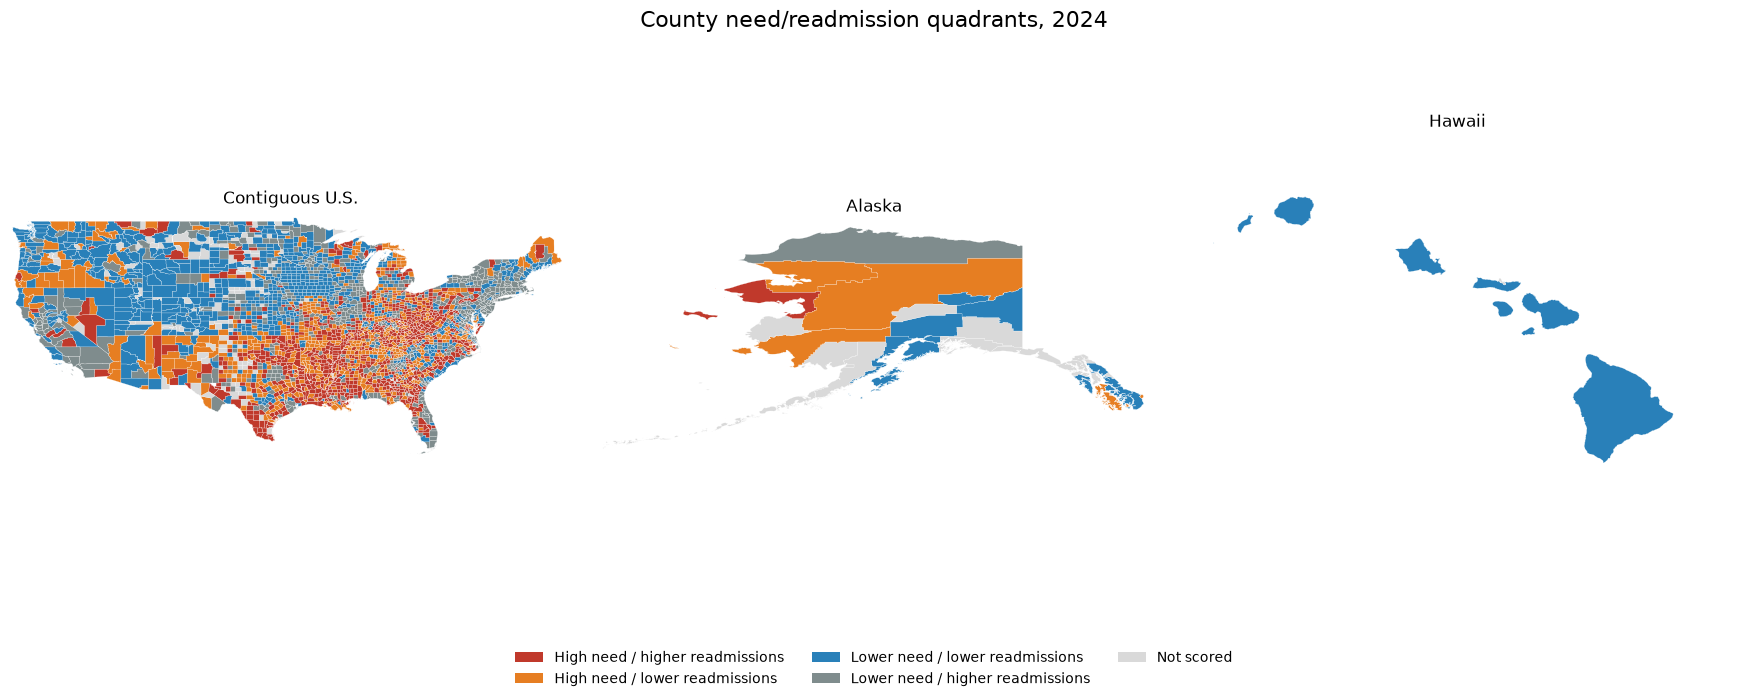

Counties scored: 2,996; not scored: 146


In [15]:
from matplotlib.patches import Patch

quadrant_colors = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / lower readmissions": "#2980b9",
    "Lower need / higher readmissions": "#7f8c8d",
}
not_scored_color = "#d9d9d9"
quadrant_by_fips = score_df.set_index("CountyFIPS")["Quadrant"]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        quadrant = quadrant_by_fips.get(county_fips)
        facecolors.append(quadrant_colors.get(quadrant, not_scored_color))

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

legend_items = [
    Patch(facecolor=color, label=label)
    for label, color in quadrant_colors.items()
]
legend_items.append(Patch(facecolor=not_scored_color, label="Not scored"))
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False)
fig.suptitle("County need/readmission quadrants, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Counties scored: {len(score_df):,}; not scored: {len(analysis_df) - len(score_df):,}")

## Map the stricter priority group

This view focuses on the stricter top-quartile definition: high NeedScore and high observed readmission rate. Red counties meet both cutoffs, gray counties have scores but do not meet both, and light gray counties lack complete scores. The map is a locator for further investigation, not a measure of quality or a causal explanation.

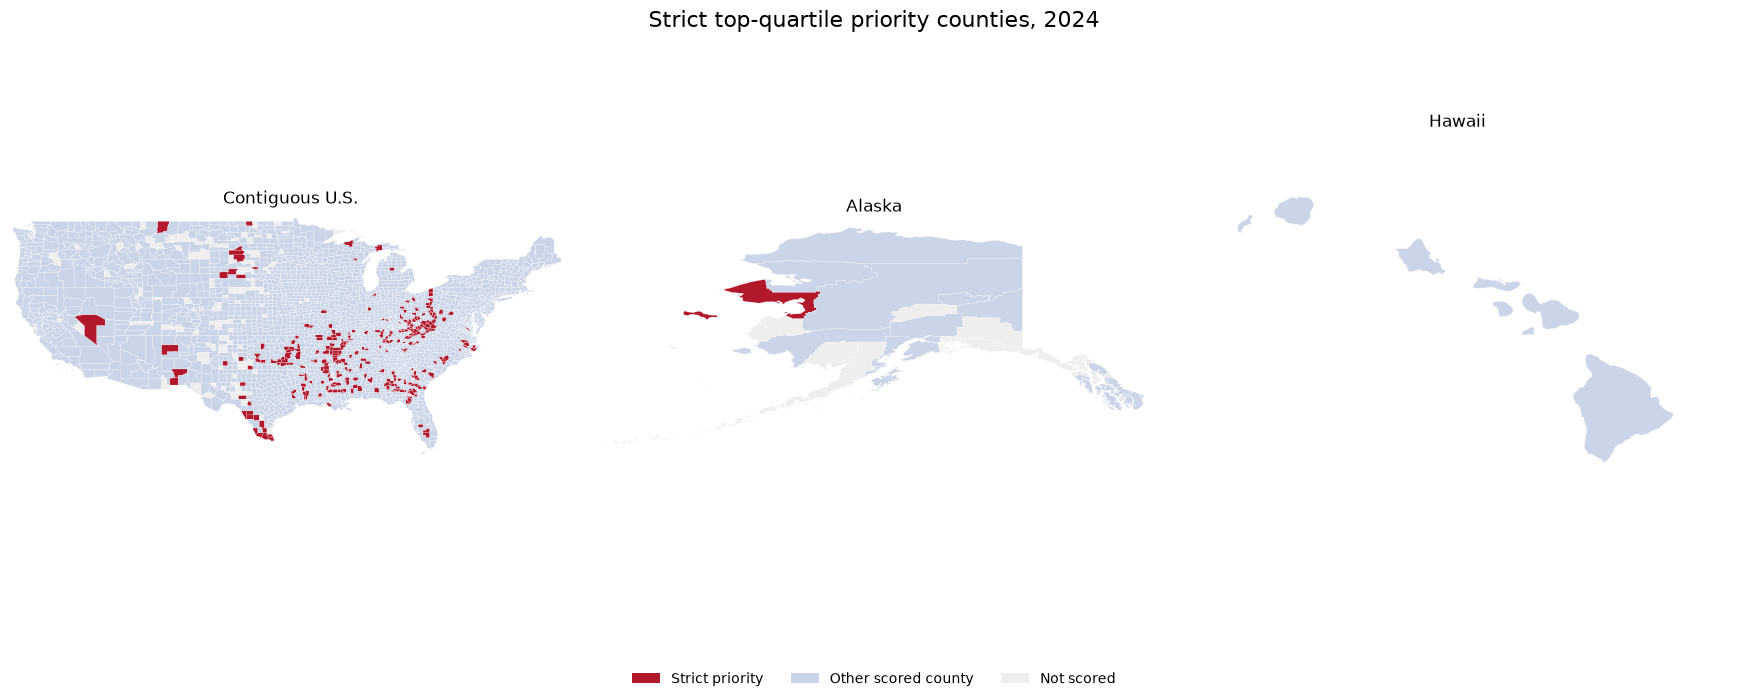

Strict priority counties mapped: 289


In [16]:
strict_by_fips = score_df.set_index("CountyFIPS")["StrictPriority"]
strict_colors = {
    "Strict priority": "#b2182b",
    "Other scored county": "#cbd5e8",
    "Not scored": "#eeeeee",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        if county_fips not in strict_by_fips.index:
            status = "Not scored"
        elif strict_by_fips.at[county_fips]:
            status = "Strict priority"
        else:
            status = "Other scored county"
        facecolors.append(strict_colors[status])

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

strict_legend = [
    Patch(facecolor=color, label=label)
    for label, color in strict_colors.items()
]
fig.legend(handles=strict_legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Strict top-quartile priority counties, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Strict priority counties mapped: {int(score_df['StrictPriority'].sum()):,}")

## Summarize strict priority counties by state

The table reports both counts and shares among counties with complete data. A state with a high share may have only a few scored counties, so read the denominator alongside the percentage.

In [17]:
strict_state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Strict_priority_counties=("StrictPriority", "sum"),
        Strict_priority_share=("StrictPriority", "mean"),
    )
)
strict_state_profile["Strict_priority_share_pct"] = (
    100 * strict_state_profile["Strict_priority_share"]
).round(1)
strict_state_profile.sort_values(
    ["Strict_priority_counties", "Strict_priority_share"],
    ascending=False,
).head(15).drop(columns="Strict_priority_share")

,Counties_scored,Strict_priority_counties,Strict_priority_share_pct
StateAbbr,,,
GA,151,30,19.9
KY,119,27,22.7
WV,55,26,47.3
TX,226,24,10.6
MS,81,22,27.2
AR,75,20,26.7
OK,76,20,26.3
TN,95,16,16.8
OH,88,15,17.0


## Compare service-use context across priority tiers

The CMS file also reports FQHC/RHC visits, outpatient visits, Medicare Advantage participation, and dual eligibility. These help describe how priority counties differ, but visit rates are utilization—not direct provider-supply or access measures. Higher or lower use is not inherently better. The tiers distinguish strict top-quartile priority counties, the remaining median-based priority group, and other scored counties.

In [18]:
priority_tier_order = [
    "Strict priority",
    "Median priority, not strict",
    "Other counties",
]
score_df["PriorityTier"] = "Other counties"
score_df.loc[score_df["Priority"], "PriorityTier"] = "Median priority, not strict"
score_df.loc[score_df["StrictPriority"], "PriorityTier"] = "Strict priority"
score_df["PriorityTier"] = pd.Categorical(
    score_df["PriorityTier"],
    categories=priority_tier_order,
    ordered=True,
)

context_indicators = {
    "FQHC/RHC visits per 1,000 beneficiaries": "FQHC_RHC_VISITS_PER_1000_BENES",
    "Outpatient visits per 1,000 beneficiaries": "OP_VISITS_PER_1000_BENES",
    "Medicare Advantage participation (CMS units)": "MA_PRTCPTN_RATE",
    "Dual eligibility (CMS units)": "BENE_DUAL_PCT",
}
context_rows = []
for tier in priority_tier_order:
    group = score_df.loc[score_df["PriorityTier"] == tier]
    for label, column in context_indicators.items():
        values = group[column].dropna()
        context_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Count with data": len(values),
            "Median": values.median(),
            "25th percentile": values.quantile(0.25),
            "75th percentile": values.quantile(0.75),
        })

context_profile = pd.DataFrame(context_rows)
context_profile.round(3)

,Priority tier,Indicator,Count with data,Median,25th percentile,75th percentile
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",286,1558.566,799.136,2693.459
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",289,4755.556,3671.706,6280.605
2,Strict priority,Medicare Advantage participation (CMS units),288,0.556,0.475,0.639
3,Strict priority,Dual eligibility (CMS units),289,0.178,0.147,0.223
4,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",559,1151.820,387.107,2292.157
5,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",559,5133.095,3978.244,6726.996
6,"Median priority, not strict",Medicare Advantage participation (CMS units),559,0.525,0.442,0.606
7,"Median priority, not strict",Dual eligibility (CMS units),559,0.141,0.110,0.182
8,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2139,808.604,197.464,2251.673
9,Other counties,"Outpatient visits per 1,000 beneficiaries",2148,5795.802,4150.974,7681.424


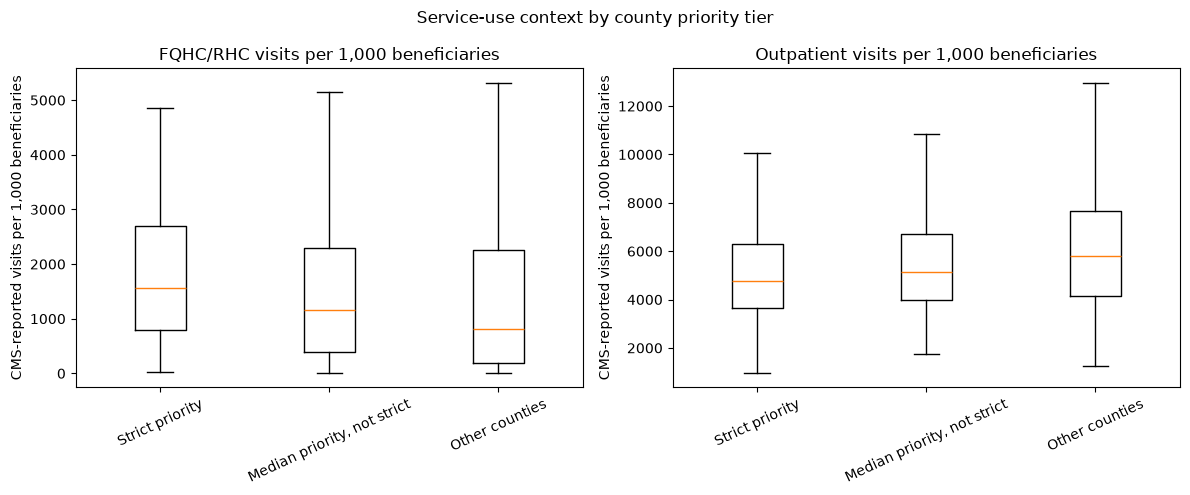

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
service_use_metrics = [
    ("FQHC_RHC_VISITS_PER_1000_BENES", "FQHC/RHC visits per 1,000 beneficiaries"),
    ("OP_VISITS_PER_1000_BENES", "Outpatient visits per 1,000 beneficiaries"),
]
for ax, (column, title) in zip(axes, service_use_metrics):
    tier_values = [
        score_df.loc[score_df["PriorityTier"] == tier, column].dropna()
        for tier in priority_tier_order
    ]
    ax.boxplot(tier_values, tick_labels=priority_tier_order, showfliers=False)
    ax.set_title(title)
    ax.set_ylabel("CMS-reported visits per 1,000 beneficiaries")
    ax.tick_params(axis="x", labelrotation=25)
fig.suptitle("Service-use context by county priority tier")
fig.tight_layout()
plt.show()

## Summarize priority candidates by state

State totals use only counties with complete values for all three CMS indicators. Priority share is more comparable than raw priority count, while the count shows the size of the flagged group. Neither is a state ranking: county size and data completeness differ.

In [20]:
state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Priority_counties=("Priority", "sum"),
        Priority_share=("Priority", "mean"),
        Median_NeedScore=("NeedScore", "median"),
        Median_readmission_rate=("ACUTE_HOSP_READMSN_PCT", "median"),
    )
)
state_profile["Priority_share_pct"] = (100 * state_profile["Priority_share"]).round(1)
state_profile.sort_values(
    ["Priority_share", "Priority_counties"], ascending=False
).head(15).drop(columns="Priority_share")

,Counties_scored,Priority_counties,Median_NeedScore,Median_readmission_rate,Priority_share_pct
StateAbbr,,,,,
WV,55,44,4.054601,0.19710,80.0
MS,81,53,3.416583,0.18510,65.4
LA,64,40,3.069725,0.17785,62.5
OK,76,43,3.246952,0.17730,56.6
KY,119,64,3.325890,0.18050,53.8
OH,88,46,2.146338,0.17785,52.3
AL,67,34,3.211199,0.17430,50.7
AR,75,38,3.947524,0.17080,50.7
GA,151,70,2.044250,0.18420,46.4


In [21]:
score_df.to_csv(
    PROJECT_ROOT / "data/processed/county_need_readmission_quadrants_2024.csv",
    index=False,
)